# Partie 3 – Flux IoT : pollution de l'air (OpenAQ API v3)

Capteurs de qualité de l'air des 8 villes de `config.py` : PM2.5, PM10, NO2, O3, CO.
Données : historique horaire (30 jours, `backfill`) + relevés `stream` (flux IoT simulé, toutes les 10 min).
Toutes les heures sont en **UTC** ; les profils journaliers sont affichés en heure de Paris.

In [1]:
import sys, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from config import CITIES
from figures.style import apply_style, save_fig, CITY_COLORS, PALETTE, STATE_COLORS
from urbanhub_utils import check_city_hourly

apply_style()
SRC = "Source : OpenAQ API v3 – collecte UrbanHub"
RAW = ROOT / "data" / "raw" / "openaq"
CLEAN = ROOT / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)

## 1. Chargement et nettoyage

In [2]:
files = glob.glob(str(RAW / "history" / "*.csv")) + glob.glob(str(RAW / "stream" / "*" / "readings.csv"))
frames = [pd.read_csv(f) for f in files]
p = pd.concat([f for f in frames if len(f)], ignore_index=True)
print(f"{len(files)} fichiers, {len(p):,} lignes brutes")

p["timestamp"] = pd.to_datetime(p["timestamp"], utc=True, format="ISO8601")
n0 = len(p)
p = p.drop_duplicates(["sensor_id", "timestamp"])
n1 = len(p)
p = p[p["value"] >= 0]                      # valeurs négatives = erreurs capteur
print(f"doublons retirés : {n0 - n1:,} | valeurs négatives retirées : {n1 - len(p):,} | lignes propres : {len(p):,}")
print("\nUnités par polluant (avant conversion) :")
print(p.groupby("pollutant")["unit"].unique())

213 fichiers, 111,299 lignes brutes
doublons retirés : 0 | valeurs négatives retirées : 0 | lignes propres : 111,299

Unités par polluant (avant conversion) :
pollutant
co      [µg/m³]
no2     [µg/m³]
o3      [µg/m³]
pm10    [µg/m³]
pm25    [µg/m³]
Name: unit, dtype: object


In [3]:
# Conversion vers µg/m³ (25 °C, 1 atm). 1 ppb = facteur × µg/m³ ; 1 ppm = 1000 ppb.
UG_PER_PPB = {"no2": 1.88, "o3": 1.96, "co": 1.145}
def to_ugm3(row_unit, pollutant, value):
    u = str(row_unit).lower().replace("µ", "u").replace("μ", "u")
    if u.startswith("ug"):
        return value
    if u == "ppb":
        return value * UG_PER_PPB[pollutant]
    if u == "ppm":
        return value * 1000 * UG_PER_PPB[pollutant]
    return np.nan
def factor(row_unit, pollutant):
    return to_ugm3(row_unit, pollutant, 1.0)
pairs = p[["pollutant", "unit"]].drop_duplicates()
pairs["facteur_vers_ugm3"] = [factor(u, pol) for pol, u in zip(pairs["pollutant"], pairs["unit"])]
print(pairs.sort_values("pollutant").to_string(index=False))
p["fac"] = [factor(u, pol) for u, pol in zip(p["unit"], p["pollutant"])]
p["value_ugm3"] = p["value"] * p["fac"]
p = p.dropna(subset=["value_ugm3"]).drop(columns="fac")
p["hour"] = p["timestamp"].dt.floor("h")
p["city"] = p["city"].astype("string")
print("\nlignes conservées :", f"{len(p):,}", "| capteurs :", p["sensor_id"].nunique(), "| période :", p["timestamp"].min(), "→", p["timestamp"].max())
p.to_parquet(CLEAN / "pollution.parquet", index=False)

pollutant  unit  facteur_vers_ugm3
       co µg/m³                1.0
      no2 µg/m³                1.0
       o3 µg/m³                1.0
     pm10 µg/m³                1.0
     pm25 µg/m³                1.0



lignes conservées : 111,299 | capteurs : 202 | période : 2026-10-22 15:00:00+00:00 → 2026-11-21 13:00:00+00:00


In [4]:
# Table ville × heure (partie 4) : moyenne des capteurs de la ville, un polluant par colonne
hourly = (p.pivot_table(index=["city", "hour"], columns="pollutant", values="value_ugm3", aggfunc="mean")
            .reset_index())
hourly.columns.name = None
hourly["city"] = hourly["city"].astype(str)
hourly = check_city_hourly(hourly.sort_values(["city", "hour"]).reset_index(drop=True))
hourly.to_parquet(CLEAN / "pollution_city_hourly.parquet", index=False)
cov = (p.groupby(["city", "pollutant"])["sensor_id"].nunique().unstack(fill_value=0))
print("Capteurs retenus par ville et polluant :"); print(cov)
hourly.head()

check_city_hourly OK : 5474 lignes, 8 villes, 2026-10-22 15:00:00+00:00 -> 2026-11-21 13:00:00+00:00
Capteurs retenus par ville et polluant :
pollutant   co  no2  o3  pm10  pm25
city                               
Bordeaux     0    6   3     6     5
Lille        0    4   3     3     6
Lyon         1    7   3     7     8
Marseille    1    4   2     4     7
Nantes       1    3   2     3     3
Paris        1   26   8    11    19
Strasbourg   0    5   3     5     5
Toulouse     0    7   4     9     7


,city,hour,co,no2,o3,pm10,pm25
0,Bordeaux,2026-10-22 15:00:00+00:00,NaN,8.600000,70.066667,10.600000,2.575
1,Bordeaux,2026-10-22 16:00:00+00:00,NaN,10.700000,66.466667,8.800000,2.600
2,Bordeaux,2026-10-22 17:00:00+00:00,NaN,18.400000,54.633333,14.550000,6.060
3,Bordeaux,2026-10-22 18:00:00+00:00,NaN,33.533333,31.233333,20.616667,8.980
4,Bordeaux,2026-10-22 19:00:00+00:00,NaN,28.600000,32.000000,19.150000,7.620


## 2. Seuils de référence OMS 2021

Moyenne sur 24 h : PM2.5 = 15, PM10 = 45, NO2 = 25 µg/m³ ; O3 = 100 µg/m³ (8 h) ; CO = 4 mg/m³ = 4 000 µg/m³.
On compare tous les polluants en **ratio OMS** (valeur / seuil) : 1 = seuil atteint. Simplification : on applique ces seuils à des moyennes horaires ou journalières, ce qui est une approximation.

In [5]:
WHO = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100, "co": 4000}
LAB = {"pm25": "PM2.5", "pm10": "PM10", "no2": "NO2", "o3": "O3", "co": "CO"}
POL_COLORS = {"pm25": PALETTE["accent"], "pm10": PALETTE["warning"], "no2": PALETTE["primary"],
              "o3": PALETTE["secondary"], "co": PALETTE["neutral"]}
p["ratio_oms"] = p["value_ugm3"] / p["pollutant"].map(WHO)
p["h_local"] = p["timestamp"].dt.tz_convert("Europe/Paris").dt.hour
p["date_local"] = p["timestamp"].dt.tz_convert("Europe/Paris").dt.normalize()

## 3. Q1 – Zones les plus polluées

Figure enregistrée : figures\p3_q1_top_sites.png


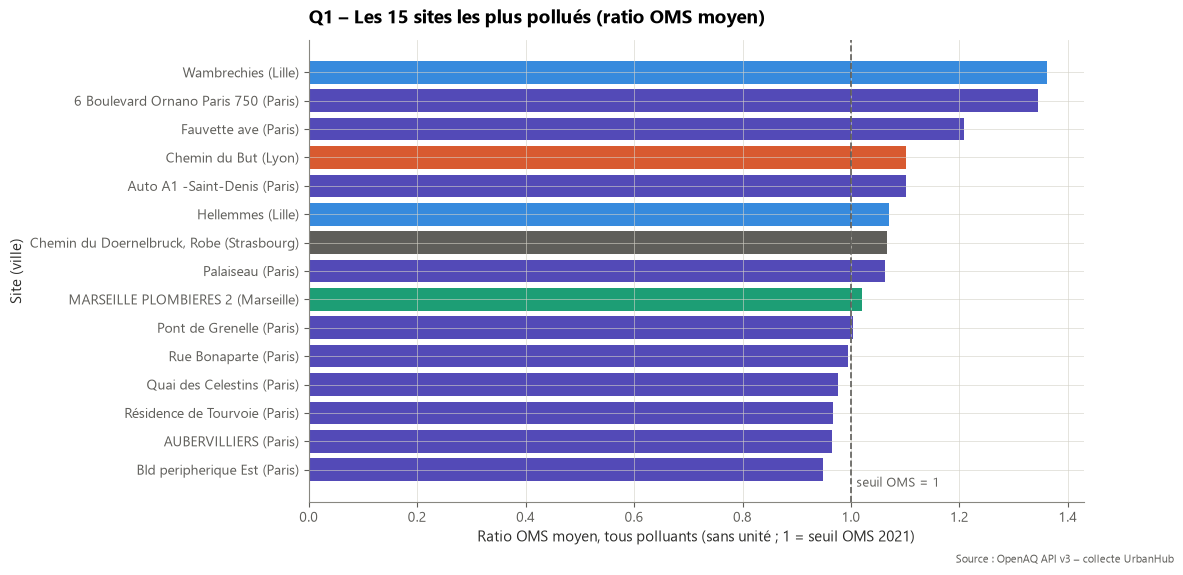

Classement par polluant (ratio OMS moyen par ville) :
pollutant     co   no2    o3  pm10  pm25
city                                    
Bordeaux     NaN  0.61  0.42  0.36  0.75
Lille        NaN  0.75  0.35  0.43  1.04
Lyon        0.07  0.79  0.32  0.35  0.74
Marseille   0.06  1.00  0.36  0.33  0.58
Nantes      0.09  0.52  0.45  0.39  0.82
Paris       0.06  0.91  0.35  0.41  0.91
Strasbourg   NaN  0.76  0.35  0.35  0.72
Toulouse     NaN  0.83  0.44  0.32  0.66

Top 5 sites :
                               label  ratio_moyen  n_polluants
                 Wambrechies (Lille)         1.36            1
6 Boulevard Ornano Paris 750 (Paris)         1.34            1
                Fauvette ave (Paris)         1.21            1
                Chemin du But (Lyon)         1.10            1
        Auto A1 -Saint-Denis (Paris)         1.10            3


In [6]:
# moyenne par capteur, puis par site (location) : ratio OMS moyen sur tous les polluants mesurés
sens = pd.read_csv(RAW / "sensors.csv")
sites = sens.drop_duplicates("location_id").set_index("location_id")[["location_name"]]
by_sensor = p.groupby(["location_id", "city", "latitude", "longitude", "pollutant"], as_index=False)["ratio_oms"].mean()
site = (by_sensor.groupby(["location_id", "city", "latitude", "longitude"], as_index=False)
        .agg(ratio_moyen=("ratio_oms", "mean"), n_polluants=("pollutant", "nunique")))
site["site"] = site["location_id"].map(sites["location_name"]).fillna(site["location_id"].astype(str))
site["label"] = site["site"].str.slice(0, 28) + " (" + site["city"] + ")"
top = site.sort_values("ratio_moyen", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["label"][::-1], top["ratio_moyen"][::-1], color=[CITY_COLORS[c] for c in top["city"][::-1]])
ax.axvline(1, color=PALETTE["neutral"], ls="--", lw=1.2); ax.text(1.01, -0.6, "seuil OMS = 1", color=PALETTE["neutral"], fontsize=9)
ax.set_title("Q1 – Les 15 sites les plus pollués (ratio OMS moyen)")
ax.set_xlabel("Ratio OMS moyen, tous polluants (sans unité ; 1 = seuil OMS 2021)"); ax.set_ylabel("Site (ville)")
save_fig("p3_q1_top_sites", source=SRC); plt.show()

print("Classement par polluant (ratio OMS moyen par ville) :")
print(p.groupby(["city", "pollutant"])["ratio_oms"].mean().unstack().round(2))
print("\nTop 5 sites :"); print(top[["label", "ratio_moyen", "n_polluants"]].head(5).round(2).to_string(index=False))

Figure enregistrée : figures\p3_q1_carte_pollution.png


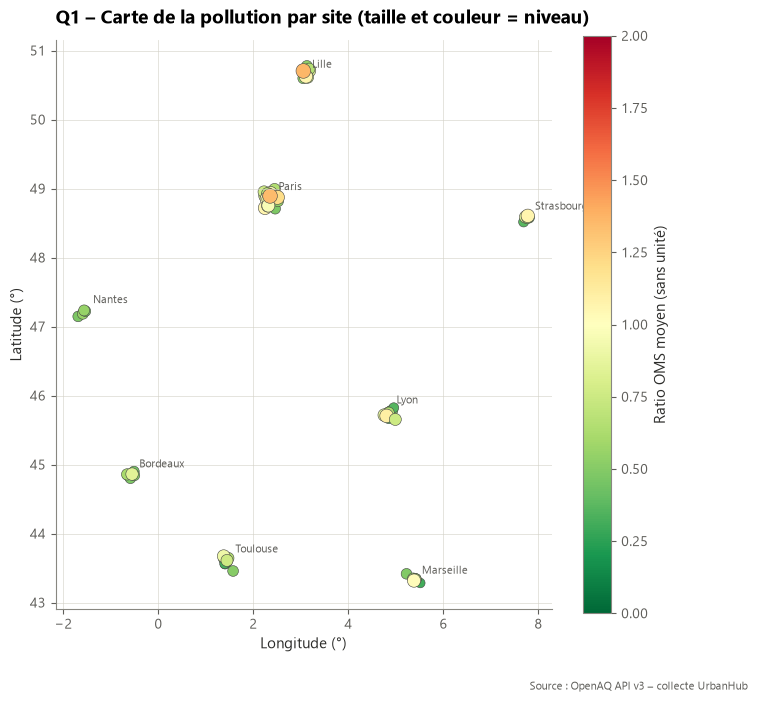

In [7]:
import folium
vmax = max(2.0, float(site["ratio_moyen"].quantile(0.95)))
m = folium.Map([46.6, 2.4], zoom_start=6, tiles="OpenStreetMap")
def col(r):
    return STATE_COLORS["high"] if r < 0.7 else STATE_COLORS["mid"] if r < 1.0 else STATE_COLORS["low"]
for r in site.dropna(subset=["latitude", "longitude"]).itertuples():
    folium.CircleMarker([r.latitude, r.longitude], radius=4 + 6 * min(r.ratio_moyen / vmax, 1.5),
                        weight=0.5, fill=True, fill_opacity=0.8, fill_color=col(r.ratio_moyen), color="#444",
                        tooltip=f"{r.site} ({r.city}) – ratio OMS {r.ratio_moyen:.2f}").add_to(m)
m.get_root().html.add_child(folium.Element(
    "<div style='position:fixed;bottom:20px;left:20px;z-index:999;background:white;padding:8px 12px;"
    "border-radius:6px;font:13px sans-serif'><b>Ratio OMS moyen</b><br>"
    f"<span style='color:{STATE_COLORS['high']}'>●</span> &lt; 0,7<br>"
    f"<span style='color:{STATE_COLORS['mid']}'>●</span> 0,7 – 1<br>"
    f"<span style='color:{STATE_COLORS['low']}'>●</span> &ge; 1 (au-dessus du seuil)</div>"))
m.save(str(ROOT / "figures" / "p3_q1_carte_pollution.html"))

# version PNG pour le rapport (France métropolitaine)
fig, ax = plt.subplots(figsize=(8, 7.5))
d = site.dropna(subset=["latitude", "longitude"])
sc = ax.scatter(d["longitude"], d["latitude"], c=d["ratio_moyen"], s=30 + 120 * d["ratio_moyen"].clip(upper=vmax) / vmax,
                cmap="RdYlGn_r", vmin=0, vmax=vmax, edgecolor="#444", linewidth=0.4)
fig.colorbar(sc, ax=ax, label="Ratio OMS moyen (sans unité)")
for c, (la, lo) in CITIES.items():
    ax.annotate(c, (lo, la), xytext=(6, 6), textcoords="offset points", fontsize=8, color=PALETTE["neutral"])
ax.set_title("Q1 – Carte de la pollution par site (taille et couleur = niveau)")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)"); ax.set_aspect(1 / np.cos(np.radians(46.5)))
save_fig("p3_q1_carte_pollution", source=SRC); plt.show()

**Méthode** : moyenne par capteur, puis par site, du ratio OMS (valeur / seuil OMS 2021), tous polluants confondus ; classement des 15 sites les plus élevés et carte (taille et couleur = niveau).

**Graphiques** : `figures/p3_q1_top_sites.png`, `figures/p3_q1_carte_pollution.png` (et la carte interactive `figures/p3_q1_carte_pollution.html`).

**Chiffre clé** : les sites les plus exposés sont Wambrechies (Lille, ratio 1,36), Boulevard Ornano (Paris, 1,34), Fauvette avenue (Paris, 1,21) et Chemin du But (Lyon, 1,10) ; Auto A1 – Saint-Denis (Paris, 1,10) est le seul de ce haut de classement à mesurer 3 polluants. Par ville, le ratio moyen le plus élevé est celui du PM2.5 à Lille (1,04), du NO2 à Marseille (1,00) et du PM2.5 / NO2 à Paris (0,91).

**Interprétation** : les zones les plus polluées sont les sites exposés au trafic (boulevards parisiens, autoroute A1, périphérie de Lille) : la pollution est surtout un phénomène de proximité routière. Plusieurs sites du classement ne mesurent qu'un seul polluant, leur ratio dépend donc de ce polluant et il faut les comparer avec prudence.

## 4. Q2 – Variation journalière

Figure enregistrée : figures\p3_q2_profil_journalier.png


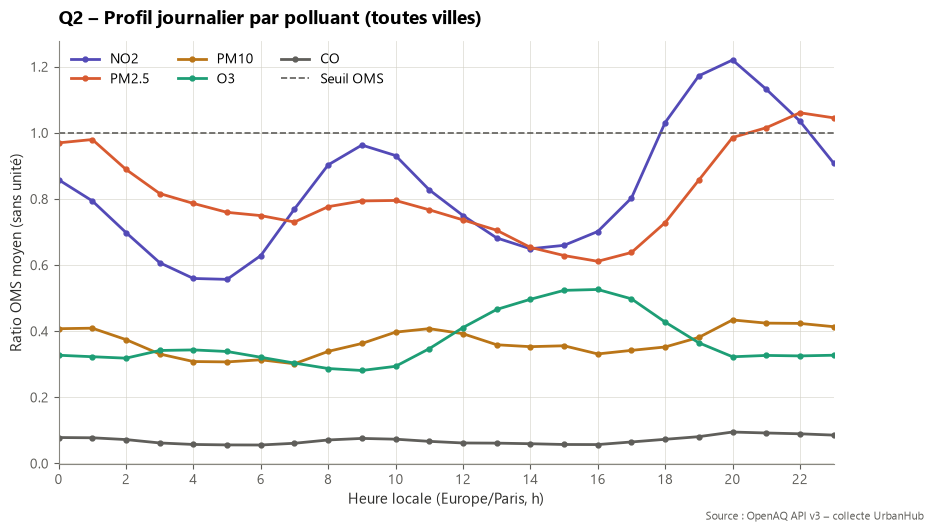

NO2 : max à 20 h (ratio 1.22), min à 5 h (ratio 0.56)
PM2.5 : max à 22 h (ratio 1.06), min à 16 h (ratio 0.61)
O3 : max à 16 h (ratio 0.53), min à 9 h (ratio 0.28)

Heure du pic NO2 par ville :
city
Bordeaux      20
Lille         20
Lyon          20
Marseille     20
Nantes        19
Paris         20
Strasbourg    19
Toulouse      20


In [8]:
prof = p.groupby(["h_local", "pollutant"])["ratio_oms"].mean().unstack()
fig, ax = plt.subplots()
for pol in ["no2", "pm25", "pm10", "o3", "co"]:
    if pol in prof: ax.plot(prof.index, prof[pol], marker="o", ms=3.5, color=POL_COLORS[pol], label=LAB[pol])
ax.axhline(1, color=PALETTE["neutral"], ls="--", lw=1.2, label="Seuil OMS")
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(0, 23)
ax.set_title("Q2 – Profil journalier par polluant (toutes villes)")
ax.set_xlabel("Heure locale (Europe/Paris, h)"); ax.set_ylabel("Ratio OMS moyen (sans unité)")
ax.legend(ncol=3)
save_fig("p3_q2_profil_journalier", source=SRC); plt.show()
for pol in ["no2", "pm25", "o3"]:
    if pol in prof:
        print(f"{LAB[pol]} : max à {int(prof[pol].idxmax())} h (ratio {prof[pol].max():.2f}), min à {int(prof[pol].idxmin())} h (ratio {prof[pol].min():.2f})")
print("\nHeure du pic NO2 par ville :")
print(p[p.pollutant == "no2"].groupby(["city", "h_local"])["ratio_oms"].mean().unstack(0).idxmax().to_string())

**Méthode** : moyenne du ratio OMS par heure locale (Europe/Paris) et par polluant, sur les 30 jours de collecte.

**Graphique** : `figures/p3_q2_profil_journalier.png`.

**Chiffre clé** : le NO2 culmine à 20 h (ratio 1,22) et est au plus bas à 5 h (0,56) ; dans 6 villes sur 8 le pic NO2 est à 20 h, dans les deux autres à 19 h. Le PM2.5 est maximal à 22 h (1,06) et minimal à 16 h (0,61). L'ozone est maximal à 16 h (0,53) et minimal à 9 h (0,28).

**Interprétation** : le NO2, polluant du trafic, suit les heures de forte circulation, avec un pic tardif (19–20 h) qu'on peut relier au trafic du soir et à une couche limite atmosphérique plus basse en automne. Le PM2.5 monte en soirée (chauffage résidentiel et trafic). L'ozone, polluant secondaire formé avec le rayonnement solaire, atteint son maximum l'après-midi, comme attendu, mais à un niveau bas en novembre.

## 5. Q3 – Polluant dominant par ville

Figure enregistrée : figures\p3_q3_polluant_dominant.png


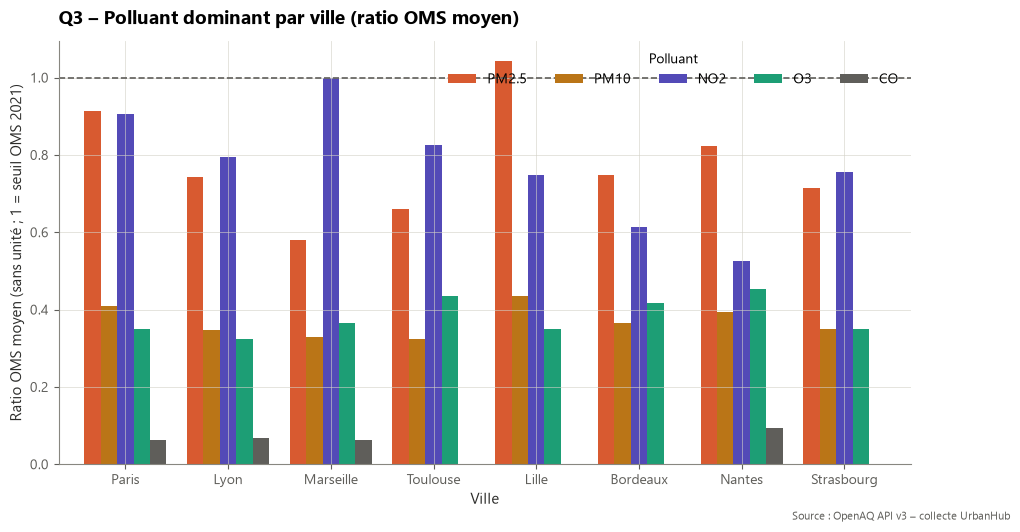

pollutant   pm25  pm10   no2    o3    co
city                                    
Paris       0.91  0.41  0.91  0.35  0.06
Lyon        0.74  0.35  0.79  0.32  0.07
Marseille   0.58  0.33  1.00  0.36  0.06
Toulouse    0.66  0.32  0.83  0.44   NaN
Lille       1.04  0.43  0.75  0.35   NaN
Bordeaux    0.75  0.36  0.61  0.42   NaN
Nantes      0.82  0.39  0.52  0.45  0.09
Strasbourg  0.72  0.35  0.76  0.35   NaN

Polluant dominant :
city
Paris         PM2.5
Lyon            NO2
Marseille       NO2
Toulouse        NO2
Lille         PM2.5
Bordeaux      PM2.5
Nantes        PM2.5
Strasbourg      NO2


In [9]:
dom = p.groupby(["city", "pollutant"])["ratio_oms"].mean().unstack()
order = [c for c in CITIES if c in dom.index]
dom = dom.loc[order, [c for c in ["pm25", "pm10", "no2", "o3", "co"] if c in dom.columns]]
ax = dom.rename(columns=LAB).plot.bar(figsize=(11, 5.5), width=0.8, color=[POL_COLORS[c] for c in dom.columns], rot=0)
ax.axhline(1, color=PALETTE["neutral"], ls="--", lw=1.2)
ax.set_title("Q3 – Polluant dominant par ville (ratio OMS moyen)")
ax.set_xlabel("Ville"); ax.set_ylabel("Ratio OMS moyen (sans unité ; 1 = seuil OMS 2021)")
ax.legend(title="Polluant", ncol=5)
save_fig("p3_q3_polluant_dominant", source=SRC); plt.show()
print(dom.round(2)); print("\nPolluant dominant :"); print(dom.idxmax(axis=1).map(LAB).to_string())

**Méthode** : ratio OMS moyen par ville et par polluant (barres groupées), pour comparer des polluants de natures différentes sur une même échelle.

**Graphique** : `figures/p3_q3_polluant_dominant.png`.

**Chiffre clé** : le polluant dominant est le PM2.5 à Paris (0,91), Lille (1,04), Bordeaux (0,75) et Nantes (0,82), et le NO2 à Lyon (0,79), Marseille (1,00), Toulouse (0,83) et Strasbourg (0,76). Le PM10 reste sous 0,45 et l'ozone sous 0,45 partout ; le CO est négligeable (≤ 0,09, mesuré dans 4 villes seulement).

**Interprétation** : en automne, la pollution urbaine est dominée par les particules fines et le dioxyde d'azote, qui frôlent ou dépassent le seuil OMS dans plusieurs villes. Les villes du Sud (Marseille, Toulouse) et de l'Est sont plutôt « NO2 », celles du Nord et de l'Ouest plutôt « PM2.5 ».

## 6. Q4 – Épisodes anormaux

Jours de dépassement du seuil OMS par ville et polluant :
pollutant   co  no2  o3  pm10  pm25
city                               
Bordeaux     0    3   0     0     8
Lille        0    6   0     1    14
Lyon         0    8   0     0     8
Marseille    0   16   0     0     2
Nantes       0    0   0     0     5
Paris        0   12   0     0    11
Strasbourg   0    7   0     0     6
Toulouse     0    7   0     0     5

Pics (z > 3) : 2
     city pollutant                date_local  moy_jour   z
    Paris        co 2026-11-07 00:00:00+01:00     568.5 3.1
Marseille        co 2026-11-07 00:00:00+01:00     462.1 3.1


Figure enregistrée : figures\p3_q4_episodes.png


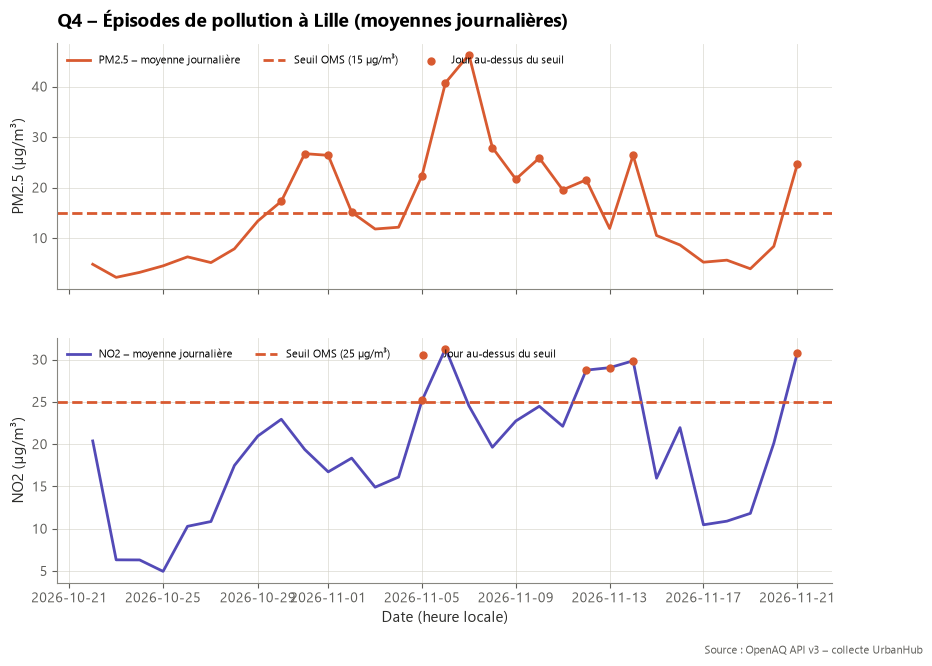

In [10]:
daily = (p.groupby(["city", "pollutant", "date_local"])["value_ugm3"].mean().rename("moy_jour").reset_index())
daily["seuil"] = daily["pollutant"].map(WHO)
daily["depasse"] = daily["moy_jour"] > daily["seuil"]
g = daily.groupby(["city", "pollutant"])["moy_jour"]
daily["z"] = (daily["moy_jour"] - g.transform("mean")) / g.transform("std")
daily["pic"] = daily["z"] > 3
res = daily.groupby(["city", "pollutant"]).agg(jours=("date_local", "nunique"), depasse=("depasse", "sum"), pics_z3=("pic", "sum")).reset_index()
print("Jours de dépassement du seuil OMS par ville et polluant :")
print(res.pivot(index="city", columns="pollutant", values="depasse").fillna(0).astype(int))
print("\nPics (z > 3) :", int(daily["pic"].sum()))
print(daily[daily["pic"]].sort_values("z", ascending=False).head(8)[["city", "pollutant", "date_local", "moy_jour", "z"]].round(1).to_string(index=False))

# ville × polluant ayant le plus de jours au-dessus du seuil (PM2.5 de préférence)
cand = res[res["pollutant"] == "pm25"].sort_values("depasse", ascending=False)
city_q4 = cand.iloc[0]["city"] if len(cand) else res.sort_values("depasse", ascending=False).iloc[0]["city"]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, pol in zip(axes, ["pm25", "no2"]):
    d = daily[(daily.city == city_q4) & (daily.pollutant == pol)].sort_values("date_local")
    ax.plot(d["date_local"], d["moy_jour"], color=POL_COLORS[pol], label=f"{LAB[pol]} – moyenne journalière")
    ax.axhline(WHO[pol], color=PALETTE["accent"], ls="--", label=f"Seuil OMS ({WHO[pol]} µg/m³)")
    dd = d[d["depasse"]]
    ax.scatter(dd["date_local"], dd["moy_jour"], color=PALETTE["accent"], s=25, zorder=3, label="Jour au-dessus du seuil")
    ax.set_ylabel(f"{LAB[pol]} (µg/m³)"); ax.legend(loc="upper left", ncol=3, fontsize=8)
axes[0].set_title(f"Q4 – Épisodes de pollution à {city_q4} (moyennes journalières)")
axes[1].set_xlabel("Date (heure locale)")
save_fig("p3_q4_episodes", source=SRC); plt.show()

**Méthode** : moyenne journalière par ville et polluant comparée au seuil OMS ; pics repérés par z-score > 3 ; graphique de la ville qui cumule le plus de jours au-dessus du seuil en PM2.5 (Lille), avec ligne horizontale au seuil.

**Graphique** : `figures/p3_q4_episodes.png`.

**Chiffre clé** : sur 30 jours, Lille dépasse le seuil PM2.5 (15 µg/m³) 14 jours, avec un pic à près de 46 µg/m³ autour du 7 novembre (environ 3 fois le seuil). Marseille dépasse le seuil NO2 16 jours, Paris 12 jours en NO2 et 11 en PM2.5. L'ozone et le CO ne dépassent jamais leur seuil. Seuls 2 pics extrêmes (z > 3) sont détectés, pour le CO le 7 novembre (Paris, Marseille).

**Interprétation** : le principal épisode de la période se situe autour du 7 novembre, avec des particules fines très élevées dans le Nord, et des dépassements NO2 répétés dans les grandes villes. Le pic de CO du 7 novembre à Paris et à Marseille le même jour suggère un phénomène commun aux deux villes ; la partie 4 testera si la météo (vent faible, absence de pluie) l'explique.

## 7. Limites

- **Durée** : 30 jours (22/10 – 21/11/2026) : l'étude décrit une période d'automne, pas un régime annuel ; l'ozone, polluant estival, est sous-représenté.
- **Couverture inégale** : de 3 capteurs de PM2.5 (Nantes) à 19 (Paris) ; le CO n'est mesuré que dans 4 villes (Paris, Lyon, Marseille, Nantes) par un capteur chacun. Les moyennes par ville dépendent de l'implantation des capteurs (sites de trafic ou de fond).
- **Seuils OMS** : définis sur 24 h (8 h pour l'O3) ; appliqués ici à des moyennes horaires ou journalières, c'est une approximation pour situer les niveaux, pas une évaluation réglementaire.
- **Unités** : toutes les mesures arrivent déjà en µg/m³ ; aucune conversion ppm/ppb n'a été nécessaire.
- **Flux IoT** : le mode `stream` interroge l'API « latest » toutes les 10 min (flux simulé) ; il complète l'historique horaire mais le volume reste limité.